# STED Data 
This code will recreate figure panels as well as plot individual dendrites and determine summary values of key variables
>  mean diam <br>
>  length <br>

In [1]:
import sys
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
#%load_ext autoreload
#%autoreload 2

import os
import glob

plot_path="../output/plots"
mypath = plot_path

import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc
from plots import plot_dsc


## Load dendritic diameter data
Set location of repo data (root folder) sets the paths for each dendrite analysed

In [2]:
from pathlib import Path
root = 'E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/'

paths ={}
paths['3wk']={'path' : root+'STED/3week_thy1_dg/tables/'}
paths['5wk']={'path' : root+'STED/5week_thy1_dg/tables/'}
paths['prox']={'path' : root+'STED/dg_proximal/tables/'}

STEDdata={}
for dataset, d in paths.items():
    #print('STEDdata'+'-'+dataset) 
    
    path_to_data=d['path']
    STEDdata[dataset]={}
    
    for File in glob.glob(path_to_data+"*Local*"):
        print(File)
        name = Path(File).name
        dendrite = 'dendrite'+name.split(' - ')[0]
        
        STEDdata[dataset][dendrite] = {'path':File} 
        STEDdata[dataset][dendrite]['file']= name
        STEDdata[dataset][dendrite]['ex_factor'] = 1
        STEDdata[dataset][dendrite]['res'] = 0.04


E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\16 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\17 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\21 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\25 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\25-2 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\27 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\28 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\29 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\29-4 - Local Diameter.csv
E:/Bonn/Data/Distal_Dendrite/Morphology/repo_data/STED/3week_thy1_dg/tables\30 - Local Diameter.

Load and analyse each branch in the STED datasets

In [3]:
for n, dataSet in STEDdata.items():
    print(n)
    
    for name, dendrite in tqdm(dataSet.items()):
        #print(name)
        #print(data[name]['path'])
        
        file_path = dendrite['path']#+dendrite['file']
        dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

3wk


  0%|          | 0/29 [00:00<?, ?it/s]

100%|██████████| 29/29 [00:00<00:00, 47.63it/s]


5wk


100%|██████████| 21/21 [00:00<00:00, 45.25it/s]


prox


100%|██████████| 15/15 [00:00<00:00, 59.84it/s]


Manually adjust DSCs 
> add DSCs missing as diam increses slighlty in the middle <br>
> remove false postives

In [4]:
###3wks
#manually add/remove DSCs
branch = STEDdata['3wk']['dendrite25']
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite28']
del branch['DSCs'][0]
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite29-4']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['3wk']['dendrite39-21']
del branch['DSCs'][2]
update_DSCs(branch)
update_compartments(branch)


branch = STEDdata['3wk']['dendrite40-4'] #update DSC properties
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[37:47].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+47]-DSC.length[DSC.length.index[0]+37]

branch = STEDdata['3wk']['dendrite41-0']
del branch['DSCs'][1]
update_DSCs(branch)
update_compartments(branch)

###5wks
#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite36-2']
DSC=branch['data'][145:270].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite38-1'] #update DSC properties missing end upswing
DSC= branch['DSCs'][0]
branch['DSC_properties'][0]['mean'] = DSC.smth[11:32].mean()
branch['DSC_properties'][0]['length'] = DSC.length[DSC.length.index[0]+32]-DSC.length[DSC.length.index[0]+11]

#manually add/remove DSCs
branch = STEDdata['5wk']['dendrite42-2']
DSC=branch['data'][50:150].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite14']
del branch['DSCs'][3]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-1']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite43-2']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

branch = STEDdata['5wk']['dendrite55']
del branch['DSCs'][0]
update_DSCs(branch)
update_compartments(branch)

### Create figure panels for Fig1 
Fig1g DSC mean diameter <br>
Fig1h DSC lenght

length mean = 1.9522497297297299 +- sem 0.21940289413890945 count 37


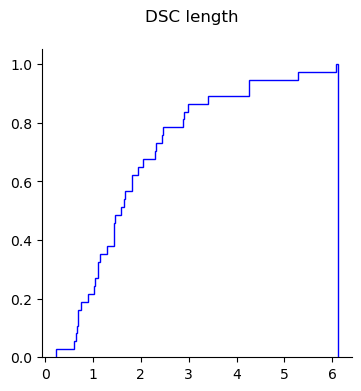

In [11]:
#select property to plot [mean, lenght]
parameter='length'

df3= summary_dsc(STEDdata['3wk'], parameter)
df5= summary_dsc(STEDdata['5wk'], parameter)
dfProx= summary_dsc(STEDdata['prox'], parameter)
df = pd.concat([df3, df5])

fig, ax = plt.subplots(figsize=(4, 4))
n_bins=200
fig.suptitle('DSC '+parameter)

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='blue', density=True, histtype='step', cumulative=True)
#ax.set_xlim([0,10])

fig.savefig(mypath+'/STED_DSC_'+parameter+'_Cumulative.svg', bbox_inches = 'tight')
print(f"{parameter} mean = {df.mean()} +- sem {df.sem()} count {df.count()}")

### Select dendrite and branch to analyse
Example dendrites shown in Fig. 1d 

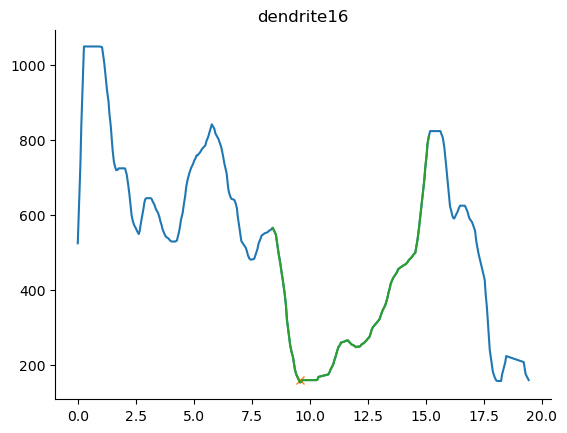

In [6]:
#data, dendrite branch
dend_name= 'dendrite16'  #'dendrite3' #'dendrite1' 'dendrite4' #'C1_02_cell1_d2'   #'C1_03_cell2_d2' 'C1_03_cell2_d3'

#branchs=dendbranch_dic[dend_name]
df=STEDdata['3wk'][dend_name]['DSC_properties']
fig, ax = plot_dsc(STEDdata['3wk'][dend_name],dend_name, corr=1)  

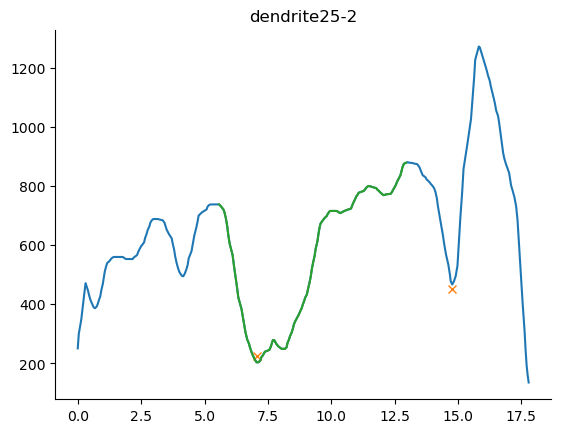

In [7]:
#data, dendrite branch
dend_name= 'dendrite25-2'  #'dendrite3' #'dendrite1' 'dendrite4' #'C1_02_cell1_d2'   #'C1_03_cell2_d2' 'C1_03_cell2_d3'

#branchs=dendbranch_dic[dend_name]
df=STEDdata['3wk'][dend_name]['DSC_properties']
fig, ax = plot_dsc(STEDdata['3wk'][dend_name],dend_name, corr=1)  

In [8]:
STEDdata['3wk'].keys()

dict_keys(['dendrite16', 'dendrite17', 'dendrite21', 'dendrite25', 'dendrite25-2', 'dendrite27', 'dendrite28', 'dendrite29', 'dendrite29-4', 'dendrite30', 'dendrite31', 'dendrite33-1', 'dendrite33-2', 'dendrite35-0', 'dendrite36-0', 'dendrite36-1', 'dendrite36-2', 'dendrite36-3', 'dendrite37', 'dendrite38', 'dendrite39-1', 'dendrite39-21', 'dendrite39-22', 'dendrite40-1', 'dendrite40-4', 'dendrite41-0', 'dendrite43', 'dendrite53', 'dendrite55'])